# Controle em cascata

**O diferencial:** usar uma medida intermediária para corrigir uma perturbação antes que ela se propague à saída principal.

Aqui há duas etapas: uma rápida, medida por `x`, e uma lenta, medida por `y`. Primeiro, observar a identificação; depois, comparar malha simples e cascata. Execute tudo e experimente os três ajustes do painel.

## O processo

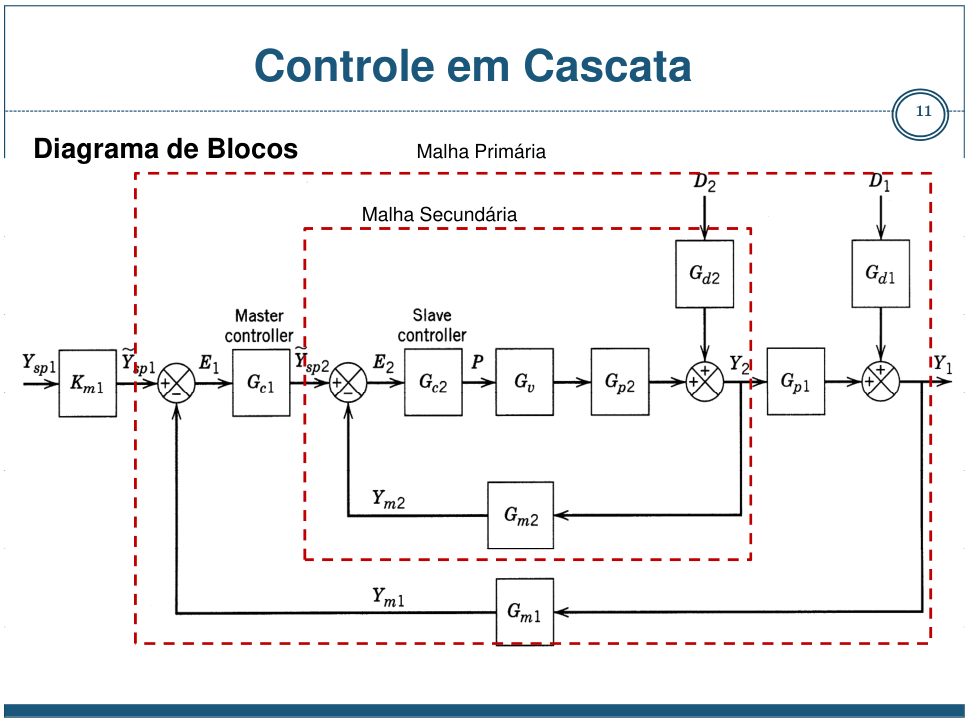

Neste esquema, a medida secundária volta ao PI interno; a principal volta ao externo. No ensaio abaixo, usar os nomes `x` e `y` para as duas medidas.

`comando → etapa rápida → x → etapa lenta → y`

Na malha simples, só `y` volta ao controlador. Na cascata, o PI externo pede um valor de `x`; o PI interno acompanha esse pedido. Os sinais são desvios normalizados, em unidades arbitrárias (u.a.), e o tempo está em segundos.

In [1]:
%pip -q install "control==0.10.2" "scipy>=1.13,<2" "numpy>=2,<3" "matplotlib>=3.8,<4" "ipywidgets>=8.1,<9"
import control as controle
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

## A planta

Usar o caso numérico publicado: $G_2(s)=3e^{-3s}/(13{,}3s+1)$ e $G_1(s)=10(1-5s)e^{-5s}/[(30s+1)^3(10s+1)^2]$.

A etapa lenta é mantida completa na simulação. O PI usa uma aproximação mais simples; as diferenças e a origem dos modelos estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/01_controle_cascata/README.md).

In [2]:
ganho_interno = 3.
constante_interna = 13.3
atraso_interno = 3.
s = controle.tf('s')
etapa_rapida_sem_atraso = ganho_interno / (constante_interna*s + 1)
etapa_lenta_sem_atraso = 10*(1 - 5*s) / ((30*s + 1)**3 * (10*s + 1)**2)

# Aproximar os atrasos só para fechar as funções de transferência.
def atraso_aproximado(segundos, ordem=3):
    return controle.tf(*controle.pade(segundos, ordem))

etapa_rapida = etapa_rapida_sem_atraso * atraso_aproximado(3)
etapa_lenta = etapa_lenta_sem_atraso * atraso_aproximado(5)

## Obter os dados do ensaio

Aplicar uma mudança na entrada da etapa rápida e guardar **tempo, entrada e saída medida**. Os exemplos são simulados, com ruído de 0,015 u.a.; não são medições experimentais do artigo.

Separar três arquivos: **ajuste**, **escolha** e **validação**. Para usar dados próprios, enviar os CSVs à pasta `dados_ensaio`, manter esses nomes e mudar `usar_ensaio_externo` para `True`. Usar desvios do ponto de operação, começar em equilíbrio e manter a mesma unidade e amostragem uniforme.

In [3]:
from pathlib import Path
from scipy import signal
from scipy.optimize import least_squares

def guardar_ensaio(nome, tempo, entrada, saida):
    pasta = Path('dados_ensaio')
    pasta.mkdir(exist_ok=True)
    np.savetxt(pasta / f'{nome}.csv', np.column_stack([tempo, entrada, saida]),
               delimiter=',', header='tempo,entrada,saida', comments='')

In [4]:
usar_ensaio_externo = False
tempo_ensaio = np.arange(0, 150.5, .5)
entradas = {
    'ajuste': np.where(tempo_ensaio >= 15, .2, 0.),
    'escolha': np.select([tempo_ensaio < 10, tempo_ensaio < 50,
                         tempo_ensaio < 95], [0., .15, -.05], default=.10),
    'validacao': np.select([tempo_ensaio < 20, tempo_ensaio < 65,
                           tempo_ensaio < 115], [0., -.12, .18], default=0.)}
if not usar_ensaio_externo:
    numerador, denominador, _ = signal.cont2discrete(([3.], [13.3, 1.]), .5)
    for indice, (nome, entrada) in enumerate(entradas.items()):
        entrada_atrasada = np.interp(tempo_ensaio - 3., tempo_ensaio, entrada, left=0)
        saida = signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)
        medicao = saida + np.random.default_rng(20261009 + indice).normal(0, .015, len(saida))
        guardar_ensaio(f'{nome}_rapida', tempo_ensaio, entrada, medicao)
print('Arquivos: dados_ensaio/{ajuste,escolha,validacao}_rapida.csv')

Arquivos: dados_ensaio/{ajuste,escolha,validacao}_rapida.csv


## Ler o ensaio

A partir daqui, a identificação recebe somente os sinais do CSV. Não fornecer os parâmetros da planta ao ajuste. Em dados adquiridos, remover os valores do ponto de operação antes de salvar o arquivo.

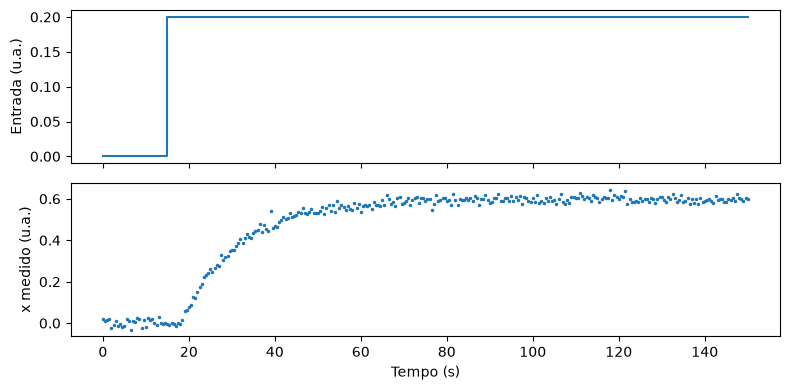

In [5]:
def ler_ensaio(nome):
    dados = np.genfromtxt(Path('dados_ensaio') / f'{nome}.csv', delimiter=',', names=True)
    tempo, entrada, saida = [np.asarray(dados[c], float) for c in ('tempo', 'entrada', 'saida')]
    if len(tempo) < 20 or not np.all(np.isfinite([tempo, entrada, saida])):
        raise ValueError('Fornecer pelo menos 20 amostras finitas de tempo, entrada e saída.')
    if not np.all(np.diff(tempo) > 0) or not np.allclose(np.diff(tempo), np.diff(tempo)[0]):
        raise ValueError('Usar amostragem uniforme, com tempo crescente.')
    if abs(entrada[0]) > 1e-10:
        raise ValueError('Remover o ponto de operação da entrada; iniciar em desvio zero.')
    return tempo - tempo[0], entrada, saida

ensaio_ajuste = ler_ensaio('ajuste_rapida')
ensaio_escolha = ler_ensaio('escolha_rapida')
ensaio_validacao = ler_ensaio('validacao_rapida')
figura, eixos = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
eixos[0].step(ensaio_ajuste[0], ensaio_ajuste[1], where='post'); eixos[0].set_ylabel('Entrada (u.a.)')
eixos[1].plot(ensaio_ajuste[0], ensaio_ajuste[2], '.', ms=3); eixos[1].set_ylabel('x medido (u.a.)')
eixos[1].set_xlabel('Tempo (s)'); plt.tight_layout(); plt.show()

## Comparar P1D, P2D e P3D

P1, P2 e P3 indicam **um, dois ou três polos reais estáveis**. O D indica atraso estimado. Ajustar ganho, constantes de tempo positivas e atraso por mínimos quadrados.

$\widehat G(s)=K e^{-\theta s}/\prod_i(\tau_i s+1)$.

Mais polos aumentam a flexibilidade e o número de parâmetros; não garantem um modelo melhor.

In [6]:
def prever_modelo(modelo, ensaio):
    tempo, entrada, _ = ensaio
    denominador = np.array([1.0])
    for constante in modelo['constantes']:
        denominador = np.convolve(denominador, [constante, 1.0])
    entrada_atrasada = np.interp(tempo - modelo['atraso'], tempo, entrada, left=0)
    numerador, denominador, _ = signal.cont2discrete(
        ([modelo['ganho']], denominador), tempo[1] - tempo[0], method='zoh')
    return signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)

def avaliar_modelo(modelo, ensaio):
    previsao = prever_modelo(modelo, ensaio)
    erro = ensaio[2] - previsao
    escala = np.linalg.norm(ensaio[2] - np.mean(ensaio[2]))
    ajuste = 100 * (1 - np.linalg.norm(erro) / escala) if escala > 0 else np.nan
    return ajuste, np.sqrt(np.mean(erro ** 2))

In [7]:
def identificar_modelo(ensaio, ordem):
    tempo, entrada, saida = ensaio
    duracao, passo = tempo[-1], tempo[1] - tempo[0]
    cauda = slice(-max(10, len(tempo) // 10), None)
    ganho_inicial = abs(np.median(saida[cauda]) / np.median(entrada[cauda]))
    if not np.isfinite(ganho_inicial) or ganho_inicial <= 0:
        raise ValueError('Usar um ensaio de ajuste com patamar final diferente de zero.')
    def montar(parametros):
        return {'ganho': parametros[0], 'constantes': np.sort(parametros[1:-1]),
                'atraso': parametros[-1], 'parametros': ordem + 2}
    limites = ([ganho_inicial / 20] + [passo / 10] * ordem + [0],
               [ganho_inicial * 20] + [duracao * 2] * ordem + [duracao / 4])
    ajustes = []
    for fracao in (0.06, 0.18):
        constantes = (np.geomspace(max(passo / 5, duracao * 0.002), duracao * fracao, ordem)
                      if ordem > 1 else [duracao * fracao])
        inicio = [ganho_inicial, *constantes, passo]
        ajuste = least_squares(lambda p: prever_modelo(montar(p), ensaio) - saida,
                               inicio, bounds=limites, x_scale='jac', max_nfev=250)
        ajustes.append(ajuste)
    melhor = min(ajustes, key=lambda resultado: resultado.cost)
    if not melhor.success:
        raise RuntimeError('O ajuste não convergiu; revisar o ensaio antes da sintonia.')
    return montar(melhor.x)

In [8]:
candidatos = {f'P{ordem}D': identificar_modelo(ensaio_ajuste, ordem)
              for ordem in (1, 2, 3)}
print('Ajustar somente o primeiro ensaio; manter os parâmetros daqui em diante.')

Ajustar somente o primeiro ensaio; manter os parâmetros daqui em diante.


## Escolher com parcimônia

Comparar as previsões no **segundo ensaio**. Entre os modelos até **1 ponto percentual** do melhor FIT, escolher o de menos parâmetros. Essa margem é uma escolha didática; não é um teste estatístico. FIT maior indica melhor previsão; pode ser negativo.

In [9]:
def escolher_modelo(candidatos, ensaio_escolha, tolerancia=1.0):
    ajustes = {nome: avaliar_modelo(modelo, ensaio_escolha)[0]
               for nome, modelo in candidatos.items()}
    melhor = max(ajustes.values())
    elegiveis = [nome for nome in candidatos if ajustes[nome] >= melhor - tolerancia]
    return min(elegiveis, key=lambda nome: (candidatos[nome]['parametros'], -ajustes[nome]))

def reduzir_modelo(modelo):
    return np.array([modelo['ganho'], np.sum(modelo['constantes']), modelo['atraso']])

Modelo     Parâmetros   FIT ajuste (%)   FIT escolha (%)
P1D                 3            93.02             90.97
P2D                 4            93.02             90.99
P3D                 5            93.01             91.00
Escolha por parcimônia: P1D


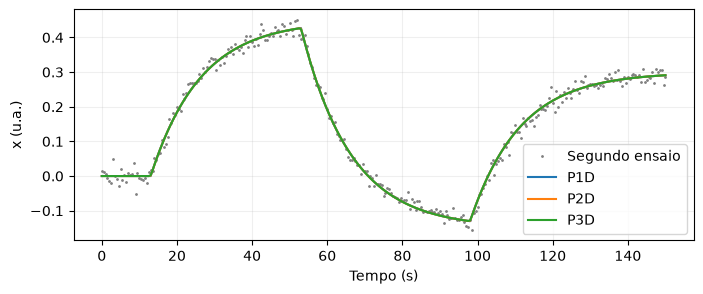

In [10]:
estrutura_escolhida = escolher_modelo(candidatos, ensaio_escolha)
modelo_escolhido = candidatos[estrutura_escolhida]
print(f"{'Modelo':<9}{'Parâmetros':>12}{'FIT ajuste (%)':>17}{'FIT escolha (%)':>18}")
for nome, modelo in candidatos.items():
    ajuste = avaliar_modelo(modelo, ensaio_ajuste)[0]
    escolha = avaliar_modelo(modelo, ensaio_escolha)[0]
    print(f"{nome:<9}{modelo['parametros']:>12}{ajuste:>17.2f}{escolha:>18.2f}")
print(f'Escolha por parcimônia: {estrutura_escolhida}')
plt.figure(figsize=(8, 3))
plt.plot(ensaio_escolha[0], ensaio_escolha[2], '.', ms=2, color='gray', label='Segundo ensaio')
for nome, modelo in candidatos.items():
    plt.plot(ensaio_escolha[0], prever_modelo(modelo, ensaio_escolha), label=nome)
plt.xlabel('Tempo (s)'); plt.ylabel('x (u.a.)'); plt.legend(); plt.grid(alpha=.2); plt.show()

## Validar o modelo escolhido

Usar o **terceiro ensaio**, com outra entrada e outro ruído. Não refazer o ajuste nem a escolha. Comparar o RMSE com a escala do ruído; conferir também o formato da resposta.

Validação final: FIT = 94.70% | RMSE = 0.0149 u.a.


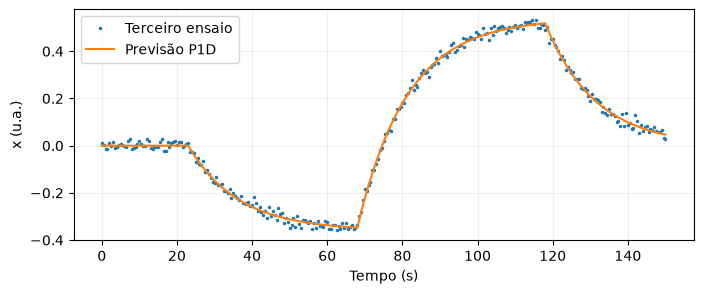

In [11]:
previsao_validacao = prever_modelo(modelo_escolhido, ensaio_validacao)
fit_validacao, rmse_validacao = avaliar_modelo(modelo_escolhido, ensaio_validacao)
print(f'Validação final: FIT = {fit_validacao:.2f}% | RMSE = {rmse_validacao:.4f} u.a.')
plt.figure(figsize=(8, 3))
plt.plot(ensaio_validacao[0], ensaio_validacao[2], '.', ms=3, label='Terceiro ensaio')
plt.plot(ensaio_validacao[0], previsao_validacao, label=f'Previsão {estrutura_escolhida}')
plt.xlabel('Tempo (s)'); plt.ylabel('x (u.a.)'); plt.legend(); plt.grid(alpha=.2); plt.show()
ganho_estimado, constante_estimada, atraso_estimado = reduzir_modelo(modelo_escolhido)

## Sintonizar por IMC

Para aplicar a regra de PI-IMC, aproximar P2D/P3D por uma primeira ordem com o mesmo ganho e atraso e $\tau_{eq}=\sum_i\tau_i$. Isso preserva o ganho estático e o primeiro momento, não a resposta inteira.

Usar $K_c=\tau_{eq}/[K(\lambda+\theta)]$ e $T_i=\tau_{eq}$. Primeiro sintonizar o PI interno; depois considerar essa malha fechada no projeto externo. Manter o tempo IMC externo em 120 s. O painel final altera o tempo IMC interno.

In [12]:
def pi_imc(ganho, constante, atraso, tempo_imc):
    ganho_controlador = constante / (ganho*(tempo_imc + atraso))
    return ganho_controlador*(1 + 1/(constante*s))

tempo_imc_externo = 120.
def montar_malhas(tempo_imc_interno=10.):
    pi_interno = pi_imc(ganho_estimado, constante_estimada, atraso_estimado, tempo_imc_interno)
    interna_fechada = controle.minreal(controle.feedback(pi_interno*etapa_rapida), verbose=False)
    # A etapa lenta tem primeiro momento de 115 s, antes do atraso.
    ganho_pi_interno = constante_estimada / (ganho_estimado*(tempo_imc_interno + atraso_estimado))
    momento_interno = constante_estimada / (3.*ganho_pi_interno)
    constante_externa = 115. + momento_interno - 3.
    pi_externo = pi_imc(10., constante_externa, 8., tempo_imc_externo)
    pi_simples = pi_imc(30., 115. + 13.3, 8., tempo_imc_externo)
    return pi_interno, interna_fechada, pi_externo, pi_simples

## O que muda ao escolher outro modelo?

Comparar o PI calculado pelo modelo escolhido com o PI de outra estrutura. Manter **a mesma planta** e **o mesmo tempo IMC**. Se as curvas quase coincidirem, aumentar a ordem não trouxe uma mudança prática relevante. Este painel é uma comparação; o experimento final usa a escolha por parcimônia.

In [13]:
def comparar_sintonias(estrutura='P2D', tempo_imc=10.):
    tempo_comparacao = np.linspace(0, 120, 481)
    referencia = np.full_like(tempo_comparacao, .2)
    plt.figure(figsize=(8, 3))
    for nome in dict.fromkeys([estrutura_escolhida, estrutura]):
        ganho, constante, atraso = reduzir_modelo(candidatos[nome])
        controlador = pi_imc(ganho, constante, atraso, tempo_imc)
        malha = controle.feedback(controlador * etapa_rapida)
        resposta = controle.forced_response(malha, tempo_comparacao, referencia).outputs
        plt.plot(tempo_comparacao, resposta, label=nome)
        print(f'{nome}: Kc = {constante/(ganho*(tempo_imc+atraso)):.3f}; Ti = {constante:.2f} s')
    plt.axhline(.2, color='gray', ls=':', label='Referência')
    plt.xlabel('Tempo (s)'); plt.ylabel('x (u.a.)'); plt.legend(); plt.grid(alpha=.2); plt.show()

estrutura = widgets.Dropdown(options=list(candidatos), value='P2D', description='Comparar')
tempo_imc_previo = widgets.FloatSlider(value=10, min=10, max=60, step=5,
    description='IMC (s)', continuous_update=False)
comparacao_imc = widgets.interactive_output(comparar_sintonias,
    {'estrutura': estrutura, 'tempo_imc': tempo_imc_previo})
display(widgets.HBox([estrutura, tempo_imc_previo]), comparacao_imc)

Output()

## Onde entra a perturbação?

Escolher uma mudança entre as etapas: ela aparece em `x` antes de alcançar `y`. Depois, trocar para uma mudança diretamente na saída principal. A medida interna não percebe imediatamente essa segunda mudança.

In [14]:
tempo = np.linspace(0, 1600, 1601)
instante_mudanca = 400.
def simular_comparacao(amplitude=.1, tempo_imc_interno=10., local='Entre as etapas'):
    _, interna, pi_externo, pi_simples = montar_malhas(tempo_imc_interno)
    sensibilidade_interna = controle.minreal(1 - interna, verbose=False)
    respostas = {}
    for nome, caminho, controlador in [('Malha simples', etapa_rapida, pi_simples),
                                       ('Cascata', interna, pi_externo)]:
        sensibilidade = controle.feedback(1, controlador*caminho*etapa_lenta)
        if local == 'Entre as etapas':
            canal_x = sensibilidade * (sensibilidade_interna if nome == 'Cascata' else 1)
            canal_y = etapa_lenta * canal_x
        else:
            canal_y = sensibilidade
            canal_x = -controlador*caminho*sensibilidade
        entrada = np.where(tempo >= instante_mudanca, amplitude, 0.)
        respostas[nome] = [np.asarray(controle.forced_response(
            controle.minreal(canal, verbose=False), tempo, entrada).outputs)
            for canal in [canal_y, canal_x]]
    return respostas

## Experimentar

1. Começar em **Entre as etapas** e comparar primeiro `x`, depois `y`.
2. Aumentar o tempo IMC interno: a correção interna fica mais lenta.
3. Trocar para **Na saída principal**. A vantagem da cascata continua igual?

A amplitude muda a intensidade do ensaio. O tempo IMC muda o controlador, não a planta.

In [15]:
def mostrar_comparacao(amplitude=.1, tempo_imc_interno=10., local='Entre as etapas'):
    respostas = simular_comparacao(amplitude, tempo_imc_interno, local)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    for nome, sinais in respostas.items():
        eixos[0].plot(tempo, sinais[0], label=nome)
        eixos[1].plot(tempo, sinais[1], label=nome)
        erro_acumulado = np.trapezoid(abs(sinais[0]), tempo)
        print(f'{nome}: erro acumulado em y = {erro_acumulado:.2f} u.a.·s')
    for eixo in eixos:
        eixo.axvline(instante_mudanca, color='gray', ls=':', lw=1)
        eixo.axhline(0, color='black', lw=.6); eixo.grid(alpha=.2)
    eixos[0].set_ylabel('Saída principal y (u.a.)'); eixos[0].legend()
    eixos[1].set_ylabel('Medida interna x (u.a.)'); eixos[1].set_xlabel('Tempo (s)')
    plt.tight_layout(); plt.show()

In [16]:
amplitude = widgets.FloatSlider(value=.1, min=.02, max=.2, step=.02,
    description='Amplitude', continuous_update=False)
tempo_interno = widgets.FloatSlider(value=10, min=10, max=60, step=5,
    description='IMC interno (s)', continuous_update=False, style={'description_width':'initial'})
local_mudanca = widgets.Dropdown(options=['Entre as etapas', 'Na saída principal'],
    description='Mudança', value='Entre as etapas')
painel = widgets.interactive_output(mostrar_comparacao,
    {'amplitude':amplitude, 'tempo_imc_interno':tempo_interno, 'local':local_mudanca})
display(widgets.VBox([local_mudanca, amplitude, tempo_interno]), painel)

Output()

A cascata acrescenta informação e uma malha de realimentação. Ela é especialmente útil quando a variável interna é rápida e mede a perturbação relevante. O gráfico não promete que duas malhas sempre serão melhores.

## Referências

Franklin, T. S.; Santos, T. L. M.; Araújo, J. M. (2020). **Critério de estabilidade simplificado para sistemas lineares em cascata com atraso variável: uma abordagem via preditor de Smith Filtrado**. CBA 2020. [Artigo](https://ojs.sba.org.br/index.php/cba/article/view/1258), eqs.20–21.

Esta toolbox usa os modelos do estudo de caso com PIs por IMC e atraso fixo; não reproduz o preditor nem a análise de atraso variável do artigo. [Teoria, bibliotecas e materiais de apoio](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/01_controle_cascata/README.md).

Imagem: recorte do diagrama de blocos, slide 11, de Bojorge, N. **Controle em Cascata**, UFF (2017). [Material institucional](https://www.professores.uff.br/ninoska/wp-content/uploads/sites/57/2017/11/Aula-25-Controle-Cascata2017_2sem17.pdf). É uma ilustração conceitual, não a figura da planta numérica do artigo.